In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import scipy as sc
from scipy.integrate import dblquad

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})
np.set_printoptions(linewidth=np.inf) #print in one row

# trikotniki

In [21]:
def K_e3(vozlisca,A):
    '''togostna matrika za trivozliščni KE
    
    (x1,y1),(x2,y2),(x3,y3) = vozlisca'''
    (x1,y1),(x2,y2),(x3,y3) = vozlisca
    #A = 0.5 * np.abs(x1*(y2-y3) + x2*(y3-y1) + x3*(y1-y2))
    K = np.array([[(x2-x3)**2+(y2-y3)**2, -((x1-x3)*(x2-x3)+(y1-y3)*(y2-y3)), (x1-x2)*(x2-x3)+(y1-y2)*(y2-y3)],
                  [-((x1-x3)*(x2-x3)+(y1-y3)*(y2-y3)), (x1-x3)**2+(y1-y3)**2, -((x1-x2)*(x1-x3)+(y1-y2)*(y1-y3))],
                  [(x1-x2)*(x2-x3)+(y1-y2)*(y2-y3), -((x1-x2)*(x1-x3)+(y1-y2)*(y1-y3)), (x1-x2)**2+(y1-y2)**2]
                  ])
    return K * 1/(4*A)
vozlisca = [[0,0],[1,1],[1/2,1]]
(x1,y1),(x2,y2),(x3,y3) = vozlisca
A = 0.5 * np.abs(x1*(y2-y3) + x2*(y3-y1) + x3*(y1-y2))
K_e3(vozlisca,A)

array([[ 0.25,  0.25, -0.5 ],
       [ 0.25,  1.25, -1.5 ],
       [-0.5 , -1.5 ,  2.  ]])

In [58]:
L=1 #širina - x
H=1 #višina - y
Nx= 100 #št. točk = št. delitev +1!
Ny=Nx
dx=L/(Nx-1)
dy=H/(Ny-1)
f = 1 #desna stran DE 'volumski izvor/ponor'

#diskretizacija
pointsall=np.zeros((Nx*Ny,2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]

št. vozlišč: 10000
št. elementov: 19602


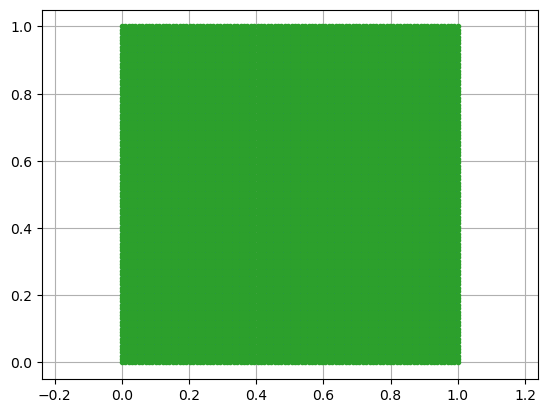

In [59]:
#triangulacija
triang = sc.spatial.Delaunay(pointsall)
elementi = triang.simplices #indeksi vozlišč po KE, shape(št.el, št.vozlišč na KE=3)
vozlisca = pointsall[triang.simplices] #koordinate vozlišč po KE, shape(št.el, št.vozlišč na KE=3, dimenzije=2)
points = triang.points #=pointsall

N_el = elementi.shape[0] #št. elementov
N_voz = pointsall.shape[0] #št. vozlišč
print('št. vozlišč:',N_voz)
print('št. elementov:',N_el)

plt.triplot(pointsall[:,0], pointsall[:,1], elementi)
plt.plot(pointsall[:,0], pointsall[:,1], '.')
plt.axis('equal')
plt.grid()

In [60]:
#zlaganje
K=np.zeros((N_voz,N_voz))
b=np.zeros(N_voz)

for i in range(N_el):
    voz = vozlisca[i]
    voz_index = elementi[i]
    (x1,y1),(x2,y2),(x3,y3) = voz
    A = 0.5 * np.abs(x1*(y2-y3) + x2*(y3-y1) + x3*(y1-y2))
    K[np.transpose([voz_index]), voz_index] += K_e3(voz,A)
    b[voz_index] += f*A/3

########### RP ###########
#Dirichlet
u_l=u_r=u_sp=u_zg=0 #non_slip
for i in range(Nx):
    #spodaj
    K[i,:] = 0
    K[i,i] = 1
    b[i] = u_sp
    #zgoraj
    K[-i,:] = 0
    K[-i,-i] = 1
    b[-i] = u_zg
for j in range(0,Ny):
    #levo
    K[j*Nx,:] = 0
    K[j*Nx,j*Nx] = 1
    b[j*Nx] = u_l
    #desno
    K[j*Nx+Nx-1,:] = 0
    K[j*Nx+Nx-1,j*Nx+Nx-1] = 1
    b[j*Nx+Nx-1] = u_r
# u_l=u_r= 1 #zgornja polovica
# for j in range(Ny//2,Ny):
#     #levo
#     K[j*Nx,:] = 0
#     K[j*Nx,j*Nx] = 1
#     b[j*Nx] = u_l
#     #desno
#     K[j*Nx+Nx-1,:] = 0
#     K[j*Nx+Nx-1,j*Nx+Nx-1] = 1
#     b[j*Nx+Nx-1] = u_r

#Neuman
# q_sp = 1
# for i in range(Nx):
#     #spodaj
#     b[i] += q_sp/3
#     #zgoraj
#     #b[-i] = q_zg
# for j in range(Ny):
#     #levo
#     b[j*Nx] = q_l
#     #desno
#     b[j*Nx+Nx-1] = q_r

In [61]:
u = sc.sparse.linalg.spsolve(K,b)

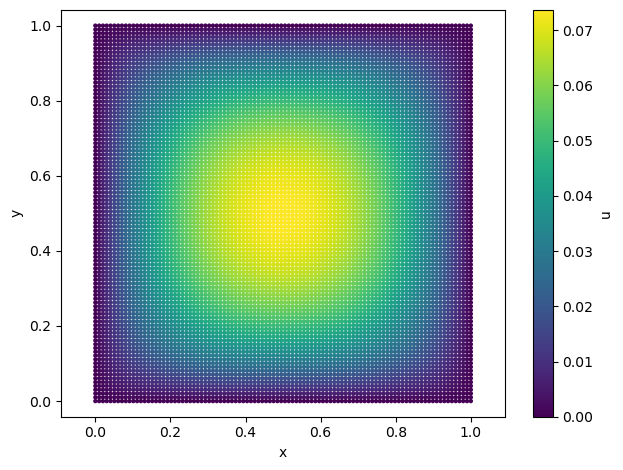

In [62]:
point_size = 10
tocke=plt.scatter(points[:,0],points[:,1], c=u, cmap='viridis', s=point_size, linewidths=0)
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(tocke, label='u')
plt.tight_layout()

In [66]:
#poiseuillov koef.
def C_MKE(u, elements, nodes):
        '''integracija po vsakem KE'''
        phi=0 #pretok
        for i in range(len(elements)):
            voz_index = elements[i]
            (x1,y1),(x2,y2),(x3,y3) = nodes[voz_index]
            A = 0.5 * np.abs(x1*(y2-y3) + x2*(y3-y1) + x3*(y1-y2))
            U = u[voz_index]
            phi+= np.sum(U*A/3)
        R=rho=eta=dp=1
        A=1
        S=np.pi**2*R**4
        C = phi * rho*np.pi*eta / (S*dp)
        return C

hitr = u.reshape(Nx,Ny)
pretok = sc.integrate.simps(sc.integrate.simps(hitr,axis=0), axis=0)
rho=eta=1#brezdim
dp=1 #desna stran DE
S=1 #površina
C = pretok * np.pi*rho*eta /(S**2*dp)

C_mke = C_MKE(u, elementi, pointsall)*10
C, C_mke

(1082.0202923314462, 0.1118331053029418)

# štirivozliščni

In [504]:
def B(vozlisca, x,y):
    (x1,y1),(x2,y2),(x3,y3),(x4,y4) = vozlisca
    b = np.array([[
        x4*(y2-y3)*(y-y4)-x3*(y-y3)*(y2-y4)+x2*(y-y2)*(y3-y4), 
        -x4*(y1-y3)*(y-y4)+x3*(y-y3)*(y1-y4)-x1*(y-y1)*(y3-y4), 
        x4*(y1-y2)*(y-y4)-x2*(y-y2)*(y1-y4)+x1*(y-y1)*(y2-y4),
        -x3*(y1 - y2)*(y - y3) + x2*(y - y2)*(y1 - y3) - x1*(y - y1)*(y2 - y3)
        ],[
        x3*x4*(y3 - y4) + x2*(x3*y2 - x4*y2 - x3*y3 + x4*y4) + x*(x4*y2 + x2*y3 - x4*y3 - x2*y4 + x3*(-y2 + y4)),
        x*x3*y1 - x1*x3*y1 - x*x4*y1 + x1*x4*y1 - x*x1*y3 + x1*x3*y3 + x*x4*y3 - x3*x4*y3 + (x1 - x3)*(x - x4)*y4,
        x2*x4*(y2 - y4) + x1*(x2*y1 - x4*y1 - x2*y2 + x4*y4) + x*(x4*y1 + x1*y2 - x4*y2 - x1*y4 + x2*(-y1 + y4)),
        x*x2*y1 - x1*x2*y1 - x*x3*y1 + x1*x3*y1 - x*x1*y2 + x1*x2*y2 + x*x3*y2 - x2*x3*y2 + (x1 - x2)*(x - x3)*y3
        ]])
    return b / (x1*(x4*(y2 - y3)*(y1 - y4) - x3*(y1 - y3)*(y2 - y4) + x2*(y1 - y2)*(y3 - y4)) + x2*x3*(y2 - y3)*(y1 - y4) - x2*x4*(y1 - y3)*(y2 - y4) + x3*x4*(y1 - y2)*(y3 - y4))
def K_e4(vozlisca):
    '''togostna matrika za štirivozliščni 'Melosh' KE z Gaussovo integracijo v 4 točkah

    (x1,y1),(x2,y2),(x3,y3),(x4,y4) = vozlisca'''   
    # enotočkovna gaussova integracija
    # (x1,y1),(x2,y2),(x3,y3),(x4,y4) = vozlisca
    # (xt,yt) = ((x1+x2+x3+x4)/4, (y1+y2+y3+y4)/4) #težišče
    # B_i = B(vozlisca, xt, yt)
    # I = 4 * B_i.T@B_i

    # štiritočkovna gaussova integracija
    x_i = y_i = 3**(1/2)/3
    B_i = B(vozlisca, x_i, y_i)
    I = 1*B_i.T@B_i
    B_i = B(vozlisca, x_i, -y_i)
    I += 1*B_i.T@B_i
    B_i = B(vozlisca, -x_i, y_i)
    I += 1*B_i.T@B_i
    B_i = B(vozlisca, -x_i, -y_i)
    I += 1*B_i.T@B_i
    return I
vozl = [[-1,-1],[1,-1],[1,1],[-1,1]]
K_e4(vozl)

array([[ 0.66666667, -0.16666667, -0.33333333, -0.16666667],
       [-0.16666667,  0.66666667, -0.16666667, -0.33333333],
       [-0.33333333, -0.16666667,  0.66666667, -0.16666667],
       [-0.16666667, -0.33333333, -0.16666667,  0.66666667]])

In [505]:
def N(x,y, vozlisca, Q, i=None):
    (x1,y1),(x2,y2),(x3,y3),(x4,y4) = vozlisca
    # b = np.array([
    #     [-Q*x*y*(x*(-x4*(y2 - y3)*(y - 2*y4) + x3*(y - 2*y3)*(y2 - y4) - x2*(y - 2*y2)*(y3 - y4)) - 2*x2*x3*(y2 - y3)*(y - 2*y4) + 2*x2*x4*(y - 2*y3)*(y2 - y4) - 2*x3*x4*(y - 2*y2)*(y3 - y4))],
    #     [Q*x*y*(x*(-x4*(y1 - y3)*(y - 2*y4) + x3*(y - 2*y3)*(y1 - y4) - x1*(y - 2*y1)*(y3 - y4)) - 2*x1*x3*(y1 - y3)*(y - 2*y4) + 2*x1*x4*(y - 2*y3)*(y1 - y4) - 2*x3*x4*(y - 2*y1)*(y3 - y4))],
    #     [-Q*x*y*(x*(-x4*(y1 - y2)*(y - 2*y4) + x2*(y - 2*y2)*(y1 - y4) - x1*(y - 2*y1)*(y2 - y4)) - 2*x1*x2*(y1 - y2)*(y - 2*y4) + 2*x1*x4*(y - 2*y2)*(y1 - y4) - 2*x2*x4*(y - 2*y1)*(y2 - y4))],
    #     [Q*x*y*(x*(-x3*(y1 - y2)*(y - 2*y3) + x2*(y - 2*y2)*(y1 - y3) - x1*(y - 2*y1)*(y2 - y3)) - 2*x1*x2*(y1 - y2)*(y - 2*y3) + 2*x1*x3*(y - 2*y2)*(y1 - y3) - 2*x2*x3*(y - 2*y1)*(y2 - y3))]
    #     ])
    b = np.array([
        [-Q * x * y * (x * (-x4 * (y2 - y3) * (y - 2 * y4) + x3 * (y - 2 * y3) * (y2 - y4) - x2 * (y - 2 * y2) * (y3 - y4)) - 2 * x2 * x3 * (y2 - y3) * (y - 2 * y4) + 2 * x2 * x4 * (y - 2 * y3) * (y2 - y4) - 2 * x3 * x4 * (y - 2 * y2) * (y3 - y4))],
        [ Q * x * y * (x * (-x4 * (y1 - y3) * (y - 2 * y4) + x3 * (y - 2 * y3) * (y1 - y4) - x1 * (y - 2 * y1) * (y3 - y4)) - 2 * x1 * x3 * (y1 - y3) * (y - 2 * y4) + 2 * x1 * x4 * (y - 2 * y3) * (y1 - y4) - 2 * x3 * x4 * (y - 2 * y1) * (y3 - y4))],
        [-Q * x * y * (x * (-x4 * (y1 - y2) * (y - 2 * y4) + x2 * (y - 2 * y2) * (y1 - y4) - x1 * (y - 2 * y1) * (y2 - y4)) - 2 * x1 * x2 * (y1 - y2) * (y - 2 * y4) + 2 * x1 * x4 * (y - 2 * y2) * (y1 - y4) - 2 * x2 * x4 * (y - 2 * y1) * (y2 - y4))],
        [ Q * x * y * (x * (-x3 * (y1 - y2) * (y - 2 * y3) + x2 * (y - 2 * y2) * (y1 - y3) - x1 * (y - 2 * y1) * (y2 - y3)) - 2 * x1 * x2 * (y1 - y2) * (y - 2 * y3) + 2 * x1 * x3 * (y - 2 * y2) * (y1 - y3) - 2 * x2 * x3 * (y - 2 * y1) * (y2 - y3))]
        ])
    if i==None:
        return b.flatten() / (4*(x1*(x4*(y2 - y3)*(y1 - y4) - x3*(y1 - y3)*(y2 - y4) + x2*(y1 - y2)*(y3 - y4)) + x2*x3*(y2 - y3)*(y1 - y4) - x2*x4*(y1 - y3)*(y2 - y4) + x3*x4*(y1 - y2)*(y3 - y4)))
    else: 
        return b[i] / (4*(x1*(x4*(y2 - y3)*(y1 - y4) - x3*(y1 - y3)*(y2 - y4) + x2*(y1 - y2)*(y3 - y4)) + x2*x3*(y2 - y3)*(y1 - y4) - x2*x4*(y1 - y3)*(y2 - y4) + x3*x4*(y1 - y2)*(y3 - y4)))
def Q_eq4_spl(vozlisca,Q=0,i=False):
    '''vektor ekvivalentnih vozliščnih izvorov za štirivozliščni 'Melosh' KE

    (x1,y1),(x2,y2),(x3,y3),(x4,y4) = vozlisca'''
    if i:
        # površinski integral
        I=np.zeros((4))
        for i in range(4):
            I[i], err = sc.integrate.dblquad(N, -1,1, -1.,1., args=(vozlisca,Q,i), epsabs=1e1)
        #I = sc.integrate.dblquad(N, -1,1, -1.,1., args=(vozlisca,Q,i))[0]
    else:
        # štiritočkovna Gaussova integracija  
        x_i = y_i = 3**(1/2)/3
        I = 1*N(x_i, y_i, vozlisca, Q)
        I += 1*N(x_i, -y_i, vozlisca, Q)
        I += 1*N(-x_i, y_i, vozlisca, Q)
        I += 1*N(-x_i, -y_i, vozlisca, Q)
    return I
def Q_eq4(Q,A):
    '''vektor ekvivalentnih vozliščnih izvorov za štirivozliščni 'Melosh' KE, kjer Q = konst!'''
    b = np.array([A/4, A/4, A/4, A/4])
    return b * Q
def area(vozlisca):
    '''izračun površine iz vozlišč za pravokotne KE nekostantne velikosti'''
    (x1,y1),(x2,y2),(x3,y3),(x4,y4) = vozlisca
    return 0.5 * np.abs((x1*y2 + x2*y3 + x3*y4 + x4*y1) - (y1*x2 + y2*x3 + y3*x4 + y4*x1))
Q_eq4(f,A=1)

array([-0.25, -0.25, -0.25, -0.25])

In [506]:
def K_izo4(k0, koord):
    '''štirivozliščni izoparametrični KE'''
    koord = np.array(koord) #kartezijev KS
    
    # naravni koordinatni sistem
    x = np.array([-1, 1, 1, -1])
    y = np.array([-1, -1, 1, 1])
    
    def jacobian(xi, yi):
        dx_dxi = sum(koord[i][0] * x[i] * 0.25 * (1 + y[i] * yi) for i in range(4))
        dx_dyi = sum(koord[i][0] * x[i] * 0.25 * (1 + x[i] * xi) for i in range(4))
        dy_dxi = sum(koord[i][1] * y[i] * 0.25 * (1 + y[i] * yi) for i in range(4))
        dy_dyi = sum(koord[i][1] * y[i] * 0.25 * (1 + x[i] * xi) for i in range(4))
        return np.array([[dx_dxi, dx_dyi], [dy_dxi, dy_dyi]])
    def integrand(xi, yi):
        jac = jacobian(xi, yi)
        print(jac)
        jac_det = np.linalg.inv(jac)
        jac_inv = np.linalg.inv(jac)
        dN = np.array([x[i]/4 for i in range(4)],
                      [y[i]/4 for i in range(4)])
        k1 = jac_inv @ dN.T
        k2 = jac_inv @ dN
        print(k1.T@k2 * jac_det)
        return k1.T@k2 * jac_det
    
    integral, _ = integrand(x,y) #dblquad(integrand, -1, 1, lambda x: -1, lambda x: 1)
    return k0 * integral

# k0 = 1
# koord0 = [(-1, -1), (1, -1), (1, 1), (-1, 1)]
# Kel = Kel4(k0, koord0)
# print(Kel)

In [507]:
#test Gauss
def B_test(x,y):
    return x**2+y**2
I = 4*B_test(0, 0) #enotočkovno ni OK na območju x,y=[-1,1]
I=0
x_i = y_i = 3**(1/2)/3
I += B_test(x_i, y_i)
I += B_test(x_i, -y_i)
I += B_test(-x_i, -y_i)
I += B_test(-x_i, y_i)
I #DELUJE!!!

2.6666666666666665

In [508]:
# L=1 #širina - x
# H=1 #višina - y
# Nx=1 + 30 #št. točk = št. delitev +1!
# Ny=Nx
# dx=L/(Nx-1)
# dy=H/(Ny-1)
# f = -1 #desna stran DE 'volumski izvor/ponor'

# #diskretizacija
# pointsall=np.zeros((Nx*Ny,2))
# for j in range(Ny):
#     for i in range(Nx):
#         index = j*Nx+i
#         pointsall[index] = [i*dx, j*dy]

# mesh
elementi = []
for j in range(Ny - 1):
    for i in range(Nx - 1):
        index = j*Nx + i
        elementi.append([index, index + 1, index + Nx + 1, index + Nx])
elementi = np.array(elementi)

N_el = elementi.shape[0]
N_voz = pointsall.shape[0]
print('št. vozlišč:',N_voz)
print('št. elementov:',N_el)

št. vozlišč: 10000
št. elementov: 9801


(-0.05, 1.05, -0.05, 1.05)

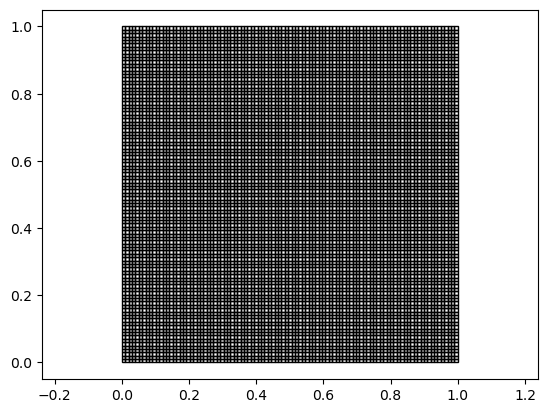

In [509]:
for el in elementi:
    plt.fill(pointsall[el,0],pointsall[el,1],edgecolor='k',fill=False)
plt.axis('equal')

In [510]:
#zlaganje
K=np.zeros((N_voz,N_voz))
b=np.zeros(N_voz)
A = L*dx * H*dy # constant area of KE

for i in range(N_el):
    voz_index = elementi[i]
    voz = pointsall[voz_index]
    K[np.transpose([voz_index]), voz_index] += K_e4(voz)
    #A = area(voz)
    b[voz_index] += Q_eq4(f,A)
A, N_el, A*N_el

(0.0001020304050607081, 9801, 1.0000000000000002)

In [511]:
########### RP ###########
#Dirichlet
u_l=u_r=u_sp=u_zg=0 #non_slip
for i in range(Nx):
    #spodaj
    K[i,:] = 0
    K[i,i] = 1
    b[i] = u_sp
    #plt.plot(pointsall[i,0],pointsall[i,1],'k.')
    #zgoraj
    K[-i,:] = 0
    K[-i,-i] = 1
    b[-i] = u_zg
    #plt.plot(pointsall[-i,0],pointsall[-i,1],'k.')
for j in range(0,Ny):
    #levo
    K[j*Nx,:] = 0
    K[j*Nx,j*Nx] = 1
    b[j*Nx] = u_l
    #plt.plot(pointsall[j*Nx,0],pointsall[j*Nx,1],'k.')
    #desno
    K[j*Nx+Nx-1,:] = 0
    K[j*Nx+Nx-1,j*Nx+Nx-1] = 1
    b[j*Nx+Nx-1] = u_r
    #plt.plot(pointsall[j*Nx+Nx-1,0],pointsall[j*Nx+Nx-1,1],'k.')

In [512]:
u_4 = np.linalg.solve(K,b)

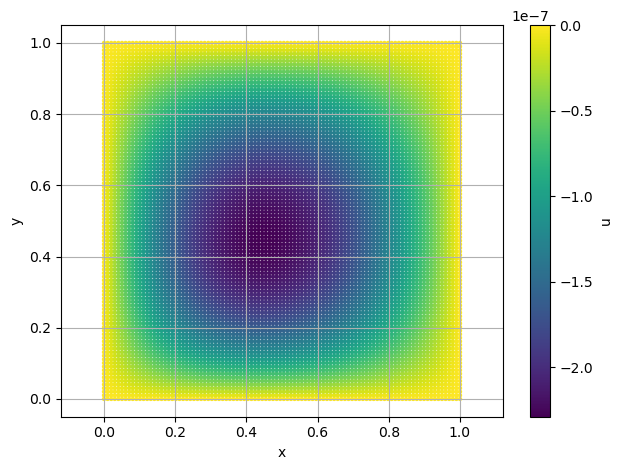

In [513]:
point_size = 10
tocke=plt.scatter(pointsall[:,0],pointsall[:,1], c=u_4, cmap='viridis', s=point_size, linewidths=0)
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(tocke, label='u')
plt.grid()
plt.tight_layout()

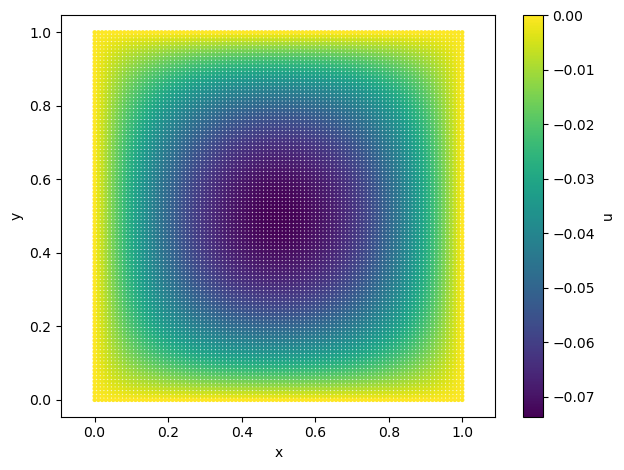

In [514]:
point_size = 10
scatter=plt.scatter(pointsall[:,0],pointsall[:,1], c=u-u_4, cmap='viridis', s=point_size, linewidths=0)
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(scatter, label='u')
plt.tight_layout()